In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
data=Path("../data/interim")
figs=Path("../docs/figs")


In [3]:
figs.mkdir(parents=True,exist_ok=True)

In [4]:
m=pd.read_parquet(data/"matches.parquet")
b=pd.read_parquet(data/"balls.parquet")


In [5]:
m["year"]=pd.to_datetime(m["date"]).dt.year

In [6]:
print("Matches:", m.shape)
print("Ball records:", b.shape)

display(m.head())

Matches: (4595, 12)
Ball records: (1115113, 16)


,match_id,date,venue,winner,result,method,team_bat_first,team_chase,first_total,second_total,chase_won,year
0,1082591,2017-04-05,Rajiv Gandhi International Stadium,Sunrisers Hyderabad,NaN,NaN,Sunrisers Hyderabad,Royal Challengers Bengaluru,207.0,172.0,0,2017
1,1082592,2017-04-06,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,NaN,NaN,Mumbai Indians,Rising Pune Supergiant,184.0,187.0,1,2017
2,1082593,2017-04-07,Saurashtra Cricket Association Stadium,Kolkata Knight Riders,NaN,NaN,Gujarat Lions,Kolkata Knight Riders,183.0,184.0,1,2017
3,1082594,2017-04-08,Holkar Cricket Stadium,Punjab Kings,NaN,NaN,Rising Pune Supergiant,Punjab Kings,163.0,164.0,1,2017
4,1082595,2017-04-08,M.Chinnaswamy Stadium,Royal Challengers Bengaluru,NaN,NaN,Royal Challengers Bengaluru,Delhi Capitals,157.0,142.0,0,2017


In [7]:
matches_year=m.groupby("year")["match_id"].nunique()

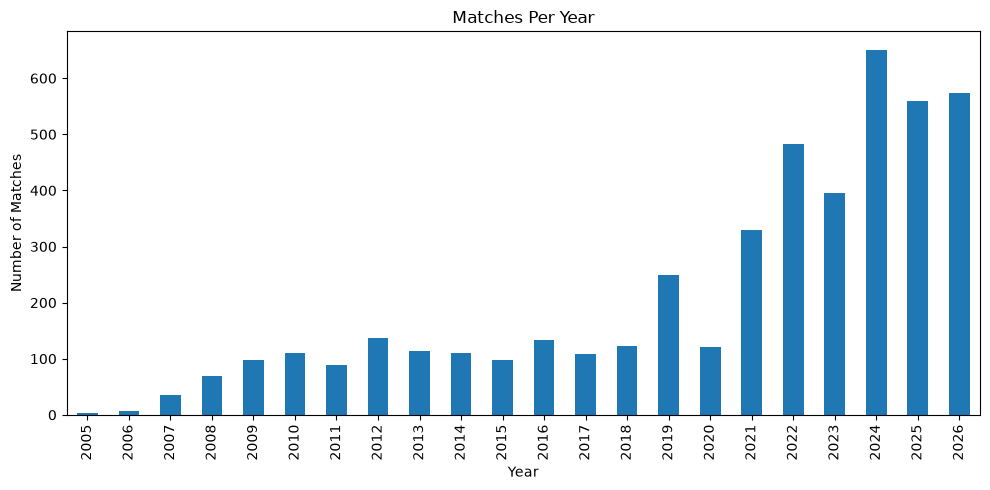

In [9]:
matches_year.plot(
    kind="bar",
    figsize=(10,5),
    title="Matches Per Year"
)
plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.savefig(figs/"matches_per_year.png",dpi=150)
plt.show()

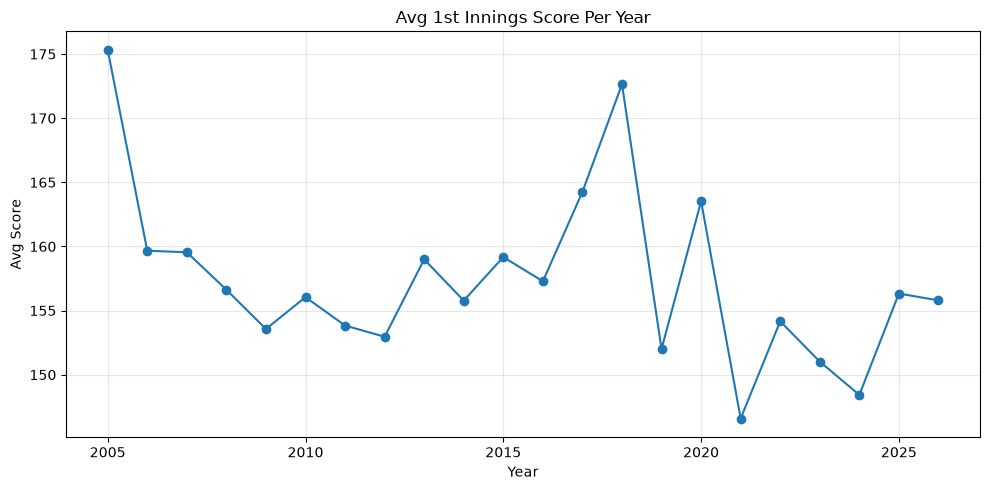

In [11]:
m.groupby("year")["first_total"].mean().plot(
    marker="o",
    figsize=(10,5),
    title="Avg 1st Innings Score Per Year"

)

plt.xlabel("Year")
plt.ylabel("Avg Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figs/"avg_per_year.png",dpi=150)
plt.show()

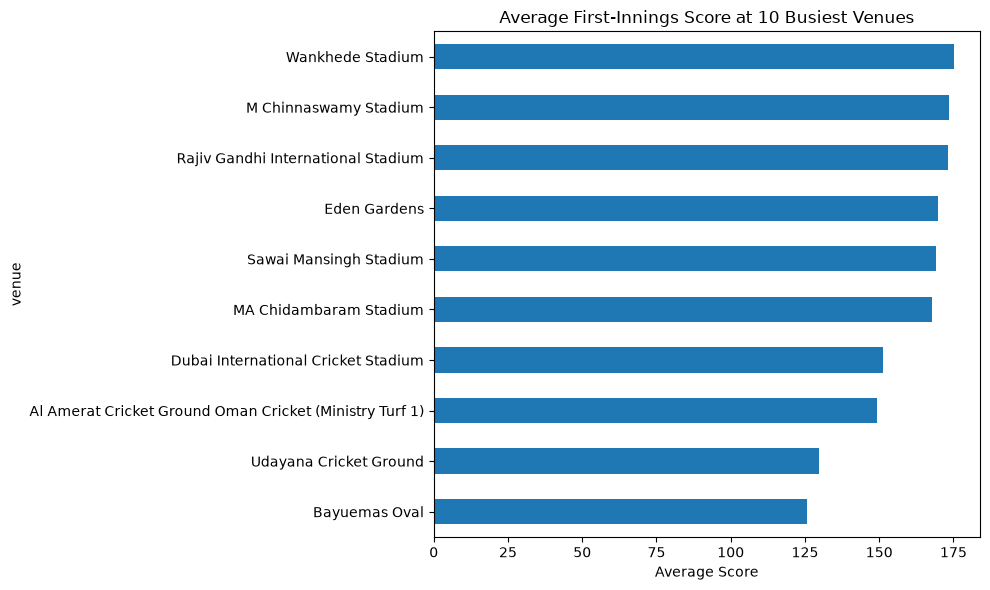

In [13]:
top_10 = (
    m.groupby("venue")["match_id"]
    .nunique()
    .nlargest(10)
    .index
)

venue_scores = (
    m[m["venue"].isin(top_10)]
    .groupby("venue")["first_total"]
    .mean()
    .sort_values()
)

venue_scores.plot(
    kind="barh",
    figsize=(10, 6),
    title="Average First-Innings Score at 10 Busiest Venues"
)

plt.xlabel("Average Score")
plt.tight_layout()
plt.savefig(figs / "venue_avg_score.png", dpi=150)
plt.show()

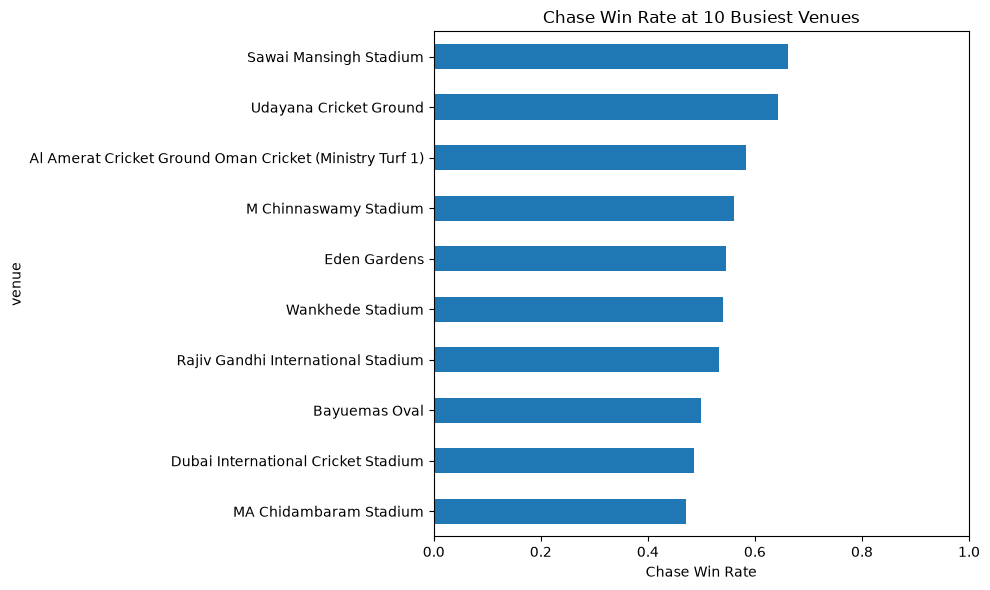

In [15]:
venue_chase = (
    m[m["venue"].isin(top_10)]
    .groupby("venue")["chase_won"]
    .mean()
    .sort_values()
)

venue_chase.plot(
    kind="barh",
    figsize=(10, 6),
    title="Chase Win Rate at 10 Busiest Venues"
)

plt.xlabel("Chase Win Rate")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(figs / "venue_chase_win_rate.png", dpi=150)
plt.show()

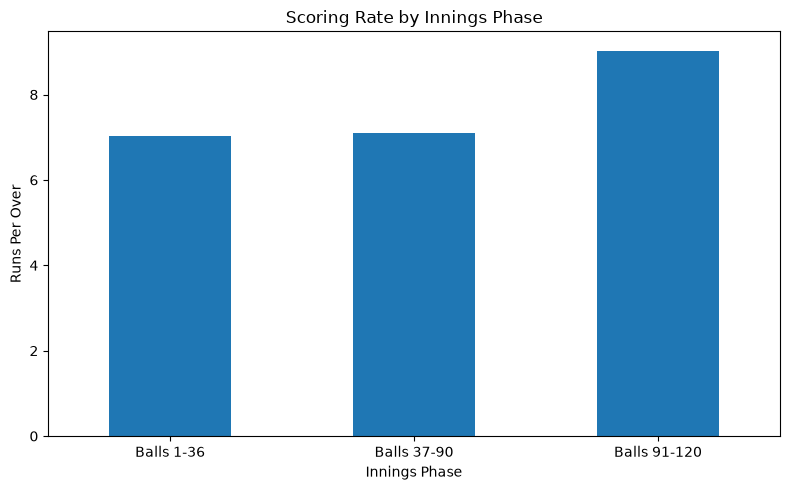

In [16]:
first_balls = b[b["innings"] == 1].copy()

# Preserve the original delivery order
first_balls["legal_ball"] = (
    first_balls.groupby("match_id")["is_legal"].cumsum()
)

first_balls = first_balls[first_balls["is_legal"] == 1].copy()

first_balls["phase"] = pd.cut(
    first_balls["legal_ball"],
    bins=[0, 36, 90, 120],
    labels=["Balls 1-36", "Balls 37-90", "Balls 91-120"]
)

phase_runs = first_balls.groupby(
    "phase", observed=False
)["runs_total"].sum()

phase_balls = first_balls.groupby(
    "phase", observed=False
)["is_legal"].sum()

phase_rate = phase_runs / phase_balls * 6

phase_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Scoring Rate by Innings Phase"
)

plt.xlabel("Innings Phase")
plt.ylabel("Runs Per Over")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figs / "scoring_rate_by_phase.png", dpi=150)
plt.show()

In [17]:
c=pd.read_parquet(data/"chase_states.parquet")

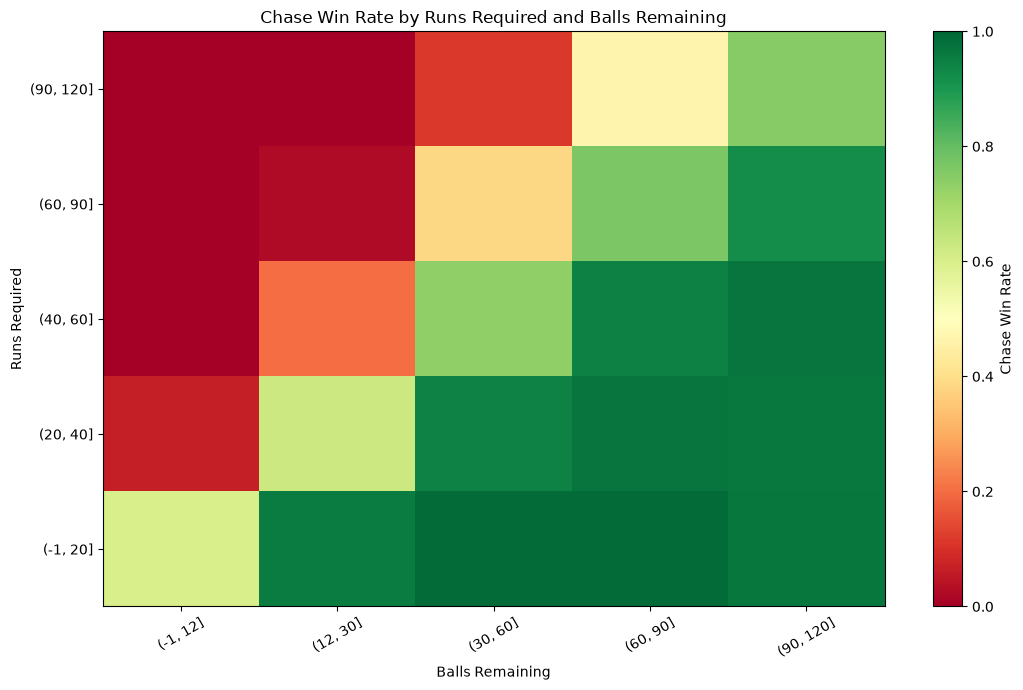

In [19]:
c["runs_needed"]=c["target"] - c["runs"]

c["need_b"]=pd.cut(
    c["runs_needed"],[-1,20,40,60,90,120]

)

c["left_b"] = pd.cut(
    c["balls_left"],
    [-1, 12, 30, 60, 90, 120]
)

# Calculate average chase win rate in each bucket
heat = c.pivot_table(
    index="need_b",
    columns="left_b",
    values="label",
    observed=False
)

# Plot heatmap
plt.figure(figsize=(11, 7))

plt.imshow(
    heat.values,
    origin="lower",
    aspect="auto",
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Chase Win Rate")

plt.xticks(
    range(len(heat.columns)),
    heat.columns.astype(str),
    rotation=30
)

plt.yticks(
    range(len(heat.index)),
    heat.index.astype(str)
)

plt.xlabel("Balls Remaining")
plt.ylabel("Runs Required")
plt.title("Chase Win Rate by Runs Required and Balls Remaining")

plt.tight_layout()

plt.savefig(
    figs / "chase_win_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

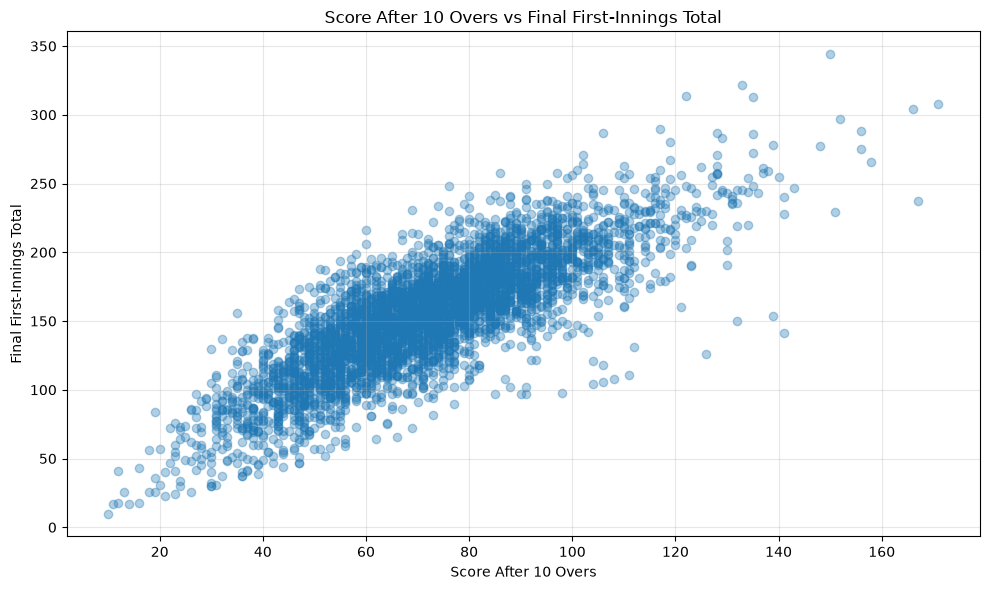

Matches plotted: 4568


In [20]:
first = pd.read_parquet(data / "first_states.parquet")
m = pd.read_parquet(data / "matches.parquet")

# Get the state after exactly 10 overs (60 legal balls)
after_10 = first[first["balls_bowled"] == 60].copy()

# Keep one observation per match
after_10 = after_10.drop_duplicates(
    subset="match_id",
    keep="last"
)

# Join with final first-innings score
projection = after_10[
    ["match_id", "runs"]
].merge(
    m[["match_id", "first_total"]],
    on="match_id",
    how="inner"
)

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    projection["runs"],
    projection["first_total"],
    alpha=0.35
)

plt.title("Score After 10 Overs vs Final First-Innings Total")
plt.xlabel("Score After 10 Overs")
plt.ylabel("Final First-Innings Total")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figs / "first_innings_projection.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Matches plotted:", projection["match_id"].nunique())

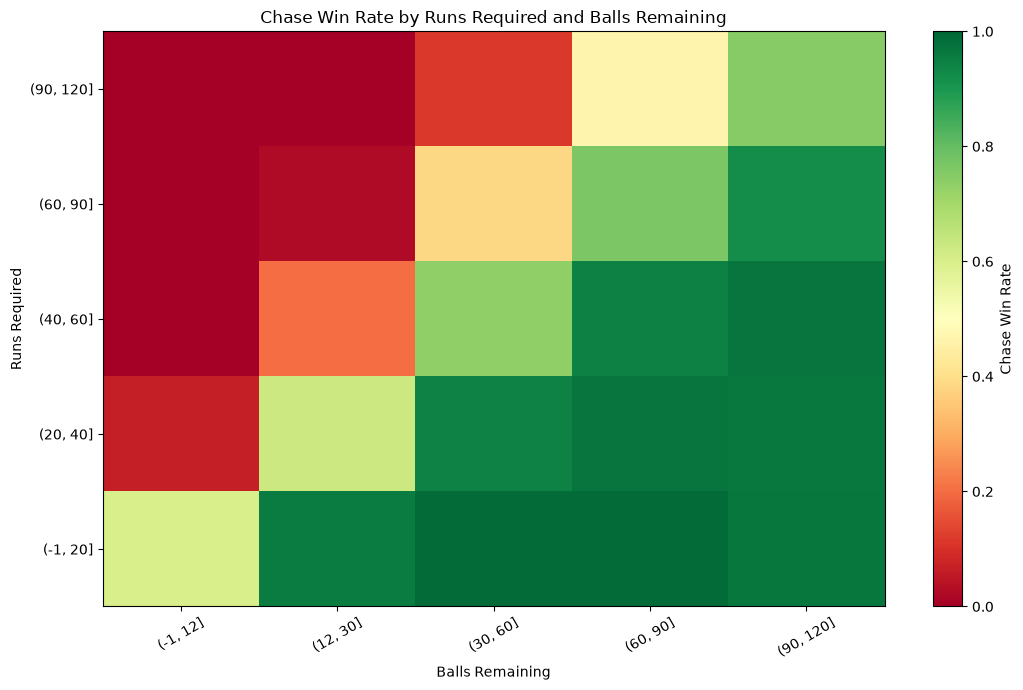

In [22]:
import numpy as np

values = heat.to_numpy(dtype=float)
masked_values = np.ma.masked_invalid(values)

plt.figure(figsize=(11, 7))

cmap = plt.cm.RdYlGn.copy()
cmap.set_bad(color="lightgray")

plt.imshow(
    masked_values,
    origin="lower",
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=1
)

plt.colorbar(label="Chase Win Rate")
plt.xticks(range(len(heat.columns)), heat.columns.astype(str), rotation=30)
plt.yticks(range(len(heat.index)), heat.index.astype(str))
plt.xlabel("Balls Remaining")
plt.ylabel("Runs Required")
plt.title("Chase Win Rate by Runs Required and Balls Remaining")
plt.tight_layout()

plt.savefig(figs / "chase_win_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
from cricketwp.features import add_state_features
import pandas as pd

DATA = "../data/interim"

chase = pd.read_parquet(f"{DATA}/chase_states.parquet")
first = pd.read_parquet(f"{DATA}/first_states.parquet")

chase_features = add_state_features(chase, chase=True)
first_features = add_state_features(first, chase=False)

print("CHASE FEATURES")
display(chase_features.describe())

print("\nFIRST-INNINGS FEATURES")
display(first_features.describe())

CHASE FEATURES


,innings,over,runs_batter,runs_total,is_wicket,is_legal,runs,wkts,balls_bowled,balls_left,wickets_in_hand,first_total,chase_won,target,label,crr,runs_needed,rrr,rrr_minus_crr,phase
count,482401.0,482401.000000,482401.000000,482401.000000,482401.000000,482401.0,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000,482401.000000
mean,2.0,8.608394,1.196828,1.222145,0.056673,1.0,67.578396,2.726248,55.132203,64.867797,7.273752,159.546630,0.478983,160.546630,0.478983,7.279448,92.968234,11.461925,4.182477,0.841868
std,0.0,5.470310,1.597882,1.595092,0.231225,0.0,44.994749,2.316859,32.841392,32.841392,2.316859,38.580632,0.499559,38.580632,0.499559,2.694793,51.851021,23.124219,23.439600,0.705884
min,2.0,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,1.000000,-1.000000,0.000000,10.000000,0.000000,11.000000,0.000000,0.000000,-5.000000,0.000000,-51.882353,0.000000
25%,2.0,4.000000,0.000000,0.000000,0.000000,1.0,30.000000,1.000000,27.000000,38.000000,6.000000,135.000000,0.000000,136.000000,0.000000,5.750000,53.000000,6.433735,-1.450980,0.000000
50%,2.0,8.000000,1.000000,1.000000,0.000000,1.0,63.000000,2.000000,54.000000,66.000000,8.000000,160.000000,0.000000,161.000000,0.000000,7.200000,91.000000,8.666667,1.654664,1.000000
75%,2.0,13.000000,1.000000,1.000000,0.000000,1.0,99.000000,4.000000,82.000000,93.000000,9.000000,184.000000,1.000000,185.000000,1.000000,8.697248,130.000000,11.228571,5.025000,1.000000
max,2.0,19.000000,7.000000,7.000000,2.000000,1.0,264.000000,10.000000,121.000000,119.000000,10.000000,344.000000,1.000000,345.000000,1.000000,60.000000,345.000000,1308.000000,1304.319328,2.000000



FIRST-INNINGS FEATURES


,innings,over,runs_batter,runs_total,is_wicket,is_legal,runs,wkts,balls_bowled,balls_left,wickets_in_hand,first_total,chase_won,final_total,label_bat_first_won,crr,phase
count,539806.0,539806.000000,539806.000000,539806.000000,539806.000000,539806.0,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000,539806.000000
mean,1.0,9.356867,1.228369,1.255129,0.057791,1.0,74.082202,2.738145,59.638639,60.361361,7.261855,155.867363,0.512588,155.867363,0.487412,7.231667,0.932789
std,0.0,5.726520,1.608149,1.603978,0.233372,0.0,50.120022,2.233999,34.397068,34.397068,2.233999,41.209922,0.499842,41.209922,0.499842,2.561772,0.735514
min,1.0,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,1.000000,-2.000000,0.000000,10.000000,0.000000,10.000000,0.000000,0.000000,0.000000
25%,1.0,4.000000,0.000000,0.000000,0.000000,1.0,33.000000,1.000000,30.000000,31.000000,6.000000,130.000000,0.000000,130.000000,0.000000,5.753425,0.000000
50%,1.0,9.000000,1.000000,1.000000,0.000000,1.0,68.000000,2.000000,59.000000,61.000000,8.000000,158.000000,1.000000,158.000000,0.000000,7.200000,1.000000
75%,1.0,14.000000,1.000000,1.000000,0.000000,1.0,108.000000,4.000000,89.000000,90.000000,9.000000,182.000000,1.000000,182.000000,1.000000,8.666667,1.000000
max,1.0,19.000000,7.000000,7.000000,2.000000,1.0,344.000000,10.000000,122.000000,119.000000,10.000000,344.000000,1.000000,344.000000,1.000000,78.000000,2.000000


In [25]:
new_columns = [
    "crr",
    "runs_needed",
    "rrr",
    "rrr_minus_crr",
    "phase"
]

print("CHASE FEATURE CHECK")
print(
    chase_features[
        ["crr", "runs_needed", "rrr", "rrr_minus_crr", "phase"]
    ].isna().sum()
)

print("\nCHASE INFINITY CHECK")
print(
    np.isinf(
        chase_features[
            ["crr", "runs_needed", "rrr", "rrr_minus_crr", "phase"]
        ]
    ).sum()
)

print("\nFIRST-INNINGS FEATURE CHECK")
print(
    first_features[["crr", "phase"]].isna().sum()
)

print("\nFIRST-INNINGS INFINITY CHECK")
print(
    np.isinf(first_features[["crr", "phase"]]).sum()
)

CHASE FEATURE CHECK
crr              0
runs_needed      0
rrr              0
rrr_minus_crr    0
phase            0
dtype: int64

CHASE INFINITY CHECK
crr              0
runs_needed      0
rrr              0
rrr_minus_crr    0
phase            0
dtype: int64

FIRST-INNINGS FEATURE CHECK
crr      0
phase    0
dtype: int64

FIRST-INNINGS INFINITY CHECK
crr      0
phase    0
dtype: int64


In [26]:
print("CHASE PHASE DISTRIBUTION")
print(chase_features["phase"].value_counts().sort_index())

print("\nFIRST-INNINGS PHASE DISTRIBUTION")
print(first_features["phase"].value_counts().sort_index())

CHASE PHASE DISTRIBUTION
phase
0    164356
1    229972
2     88073
Name: count, dtype: int64

FIRST-INNINGS PHASE DISTRIBUTION
phase
0    165372
1    245343
2    129091
Name: count, dtype: int64


In [29]:
import importlib
import cricketwp.features

importlib.reload(cricketwp.features)

from cricketwp.features import add_rolling_features

print("Rolling features imported successfully!")

Rolling features imported successfully!


In [30]:
import pandas as pd
from cricketwp.features import add_rolling_features

DATA = "../data/interim"

balls = pd.read_parquet(f"{DATA}/balls.parquet")

balls_with_momentum = add_rolling_features(balls)

display(
    balls_with_momentum[
        [
            "match_id",
            "innings",
            "over",
            "runs_total",
            "is_wicket",
            "is_legal",
            "runs_last12",
            "wkts_last12",
            "dot_pct_last12",
            "wkts_prev",
            "partnership_runs",
        ]
    ].head(20)
)

,match_id,innings,over,runs_total,is_wicket,is_legal,runs_last12,wkts_last12,dot_pct_last12,wkts_prev,partnership_runs
0,1082591,1,0,0,0,1,0.0,0.0,1.000000,0.0,0.0
1,1082591,1,0,0,0,1,0.0,0.0,1.000000,0.0,0.0
2,1082591,1,0,4,0,1,4.0,0.0,0.666667,0.0,4.0
3,1082591,1,0,0,0,1,4.0,0.0,0.750000,0.0,4.0
4,1082591,1,0,2,0,0,NaN,NaN,NaN,NaN,NaN
5,1082591,1,0,0,0,1,4.0,0.0,0.800000,0.0,4.0
6,1082591,1,0,1,0,1,5.0,0.0,0.666667,0.0,5.0
7,1082591,1,1,1,0,1,6.0,0.0,0.571429,0.0,6.0
8,1082591,1,1,4,0,1,10.0,0.0,0.500000,0.0,10.0
9,1082591,1,1,1,0,0,NaN,NaN,NaN,NaN,NaN


In [35]:
print(balls["match_id"].dtype)
print(balls["innings"].unique())

print(
    balls[balls["match_id"] == 1082591].shape
)
print(balls["match_id"].head(10).tolist())

str
[1 2]
(0, 16)
['1082591', '1082591', '1082591', '1082591', '1082591', '1082591', '1082591', '1082591', '1082591', '1082591']


In [36]:
match_id = balls["match_id"].iloc[0]

sample = balls_with_momentum[
    (balls_with_momentum["match_id"] == match_id) &
    (balls_with_momentum["innings"] == 1) &
    (balls_with_momentum["is_legal"] == True)
].copy()

display(
    sample[
        [
            "over",
            "runs_total",
            "is_wicket",
            "runs_last12",
            "wkts_last12",
            "dot_pct_last12",
            "wkts_prev",
            "partnership_runs",
        ]
    ].head(25)
)

,over,runs_total,is_wicket,runs_last12,wkts_last12,dot_pct_last12,wkts_prev,partnership_runs
0,0,0,0,0.0,0.0,1.000000,0.0,0.0
1,0,0,0,0.0,0.0,1.000000,0.0,0.0
2,0,4,0,4.0,0.0,0.666667,0.0,4.0
3,0,0,0,4.0,0.0,0.750000,0.0,4.0
5,0,0,0,4.0,0.0,0.800000,0.0,4.0
6,0,1,0,5.0,0.0,0.666667,0.0,5.0
7,1,1,0,6.0,0.0,0.571429,0.0,6.0
8,1,4,0,10.0,0.0,0.500000,0.0,10.0
10,1,6,0,16.0,0.0,0.444444,0.0,16.0
11,1,0,1,16.0,1.0,0.500000,0.0,16.0


In [38]:
momentum_columns = [
    "runs_last12",
    "wkts_last12",
    "dot_pct_last12",
    "wkts_prev",
    "partnership_runs",
]

print("NaN counts:")
print(balls_with_momentum[momentum_columns].isna().sum())

print("\nInfinity counts:")
print(
    np.isinf(
        balls_with_momentum[momentum_columns].dropna()
    ).sum()
)

NaN counts:
runs_last12         46555
wkts_last12         46555
dot_pct_last12      46555
wkts_prev           46555
partnership_runs    46555
dtype: int64

Infinity counts:
runs_last12         0
wkts_last12         0
dot_pct_last12      0
wkts_prev           0
partnership_runs    0
dtype: int64


In [39]:
legal_features = balls_with_momentum.loc[
    balls_with_momentum["is_legal"] == True,
    momentum_columns
]

print("Missing values on legal deliveries:")
print(legal_features.isna().sum())

print("Infinite values on legal deliveries:")
print(np.isinf(legal_features).sum())

Missing values on legal deliveries:
runs_last12         0
wkts_last12         0
dot_pct_last12      0
wkts_prev           0
partnership_runs    0
dtype: int64
Infinite values on legal deliveries:
runs_last12         0
wkts_last12         0
dot_pct_last12      0
wkts_prev           0
partnership_runs    0
dtype: int64
